Wierszy i kolumn: (1476, 6)
Kolumny: ['image', 'domain', 'country', 'location', 'development_stage', 'objects']
Rozmiar obrazu: (1024, 1024) | liczba kłosów: 34
Skąd zdjęcie: Utokyo_2 Japan Ripening


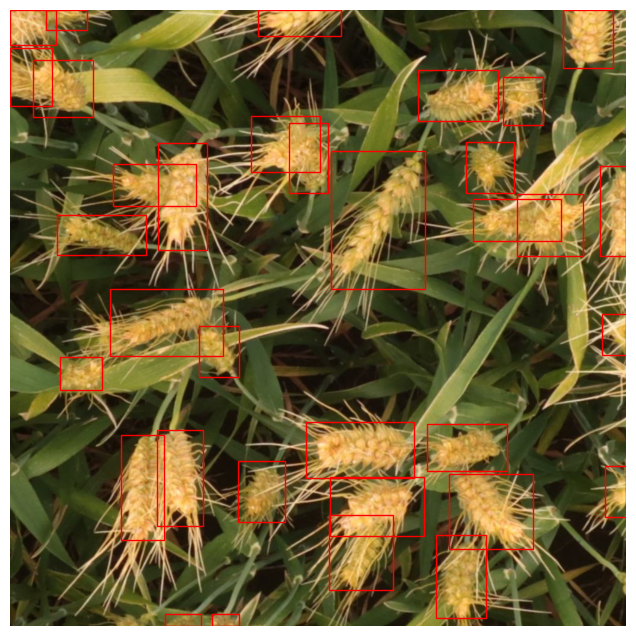

In [2]:
import io
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# 1. Wczytanie tabeli z danymi (zbiór walidacyjny - najmniejszy plik)
df = pd.read_parquet("../data/raw/gwhd_hf/validation-00000-of-00001.parquet")
print("Wierszy i kolumn:", df.shape)
print("Kolumny:", df.columns.tolist())

# 2. Wybór jednego obrazu (zmień 0 na inną liczbę, żeby zobaczyć inny)
row = df.iloc[888]
img = Image.open(io.BytesIO(row["image"]["bytes"]))  # obraz jest zapisany jako bajty
boxes = row["objects"]["boxes"]                       # lista ramek: [x, y, szerokość, wysokość]
print("Rozmiar obrazu:", img.size, "| liczba kłosów:", len(boxes))
print("Skąd zdjęcie:", row["domain"], row["country"], row["development_stage"])

# 3. Rysunek: obraz + czerwone ramki
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(img)
for x, y, w, h in boxes:
    ax.add_patch(Rectangle((x, y), w, h, fill=False, edgecolor="red"))
ax.axis("off")
plt.show()
